# EEG Decoding Workshop —  Visualization of ERD/ERS

## Notebook Outline
1. Load Raw EEG Data
2. Preprocess with MNE (Notch → Bandpass → CAR) and Epoch
   - 2-1. Remove Noise
   - 2-2. Epoch
3. Inspect Preprocessed Signals and Reject Bad Trials
4. Visualize ERD/ERS

📍 **In Google Colab, run the "Setup" cell below first.**

In [1]:
# === Setup (run first in Google Colab) ===
# Automatically skipped in local Jupyter environments.
import sys

if "google.colab" in sys.modules:
    # braindecode pulls in torch + skorch (Section 6-2); mne is the EEG toolkit.
    !pip install -q mne braindecode
    from google.colab import drive
    drive.mount("/content/drive")
    # ↓ Change this path to match where you placed the notebooks folder in Drive
    %cd /content/drive/MyDrive/MotorImageryDemo/notebooks

In [2]:
# Required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy.ndimage import uniform_filter1d
import seaborn as sns
import mne
from mne.decoding import CSP
mne.set_log_level("WARNING")

from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             cohen_kappa_score)

import utils as U  # MNE-based raw EEG loading

# Force MNE's raw-data browser to render as an inline matplotlib figure rather
# than an interactive Qt window — important for Google Colab and static
# notebook export (nbconvert / grading), where a separate Qt window can't open.
mne.viz.set_browser_backend("matplotlib")

plt.rcParams["figure.figsize"] = (9, 4)
np.random.seed(0)
print("Ready.")

Ready.


## 1. Load Raw EEG Data

Before any filtering, let's look at one recording session exactly as it came off the
headset. This is the point where you should ask: *does this look like EEG at all?*
(reasonable amplitude, visible oscillations, no flat or saturated channels).

The Emotiv EPOC X streams **14 channels named after the international 10–20 system**
(`AF3`, `F7`, `F3`, ... — no C3/C4, the classic motor-imagery sites, so we'll rely on the
nearby `FC5`/`FC6` and `F3`/`F4` electrodes later) at **128 Hz**. Each session is saved as
`recording.npz` with:

- `raw` — the (channels, samples) voltage array, in **µV**
- `timestamps` — one LSL timestamp per sample
- `marker_times` / `marker_labels` — onset time and class of each trial (0=left, 1=right, 99=rest)

We wrap this into an **`mne.io.RawArray`**, MNE's container for continuous EEG, so the rest
of the notebook can use MNE's built-in plotting and filtering instead of hand-rolled code.

In [3]:
# Dataset directory containing recording.npz files.
# Set this to a directory path to select a dataset explicitly.
# Leave it as None to use MI_DATA_DIR or the project's default data/ directory.
EEG_DATASET_PATH = "/Users/yutayamamura/Projects/MotorImageryDemo/notebooks/data/yoshioka"
# EEG_DATASET_PATH = "/path/to/your/eeg-dataset"

# Load all recording sessions under the selected directory as one MNE Raw object.
raw = U.load_raw_eeg(EEG_DATASET_PATH)
U.print_raw_summary(raw)

ch_names_raw = raw.ch_names
fs_raw = raw.info["sfreq"]

Raw EEG: 14 ch, 311444 samples, 1216.6 s, fs=256.0 Hz
Annotations: {np.str_('left'): 75, np.str_('right'): 75}


### Raw Signal Plot

`raw.plot()` draws each channel as a stacked time series, with the annotations from above
marked as colored spans. Look for: a stable baseline (no huge drift), visible high-frequency
noise from mains power (we haven't filtered anything yet), and no channel that's flat or
pinned at one value (a sign of a bad electrode contact).

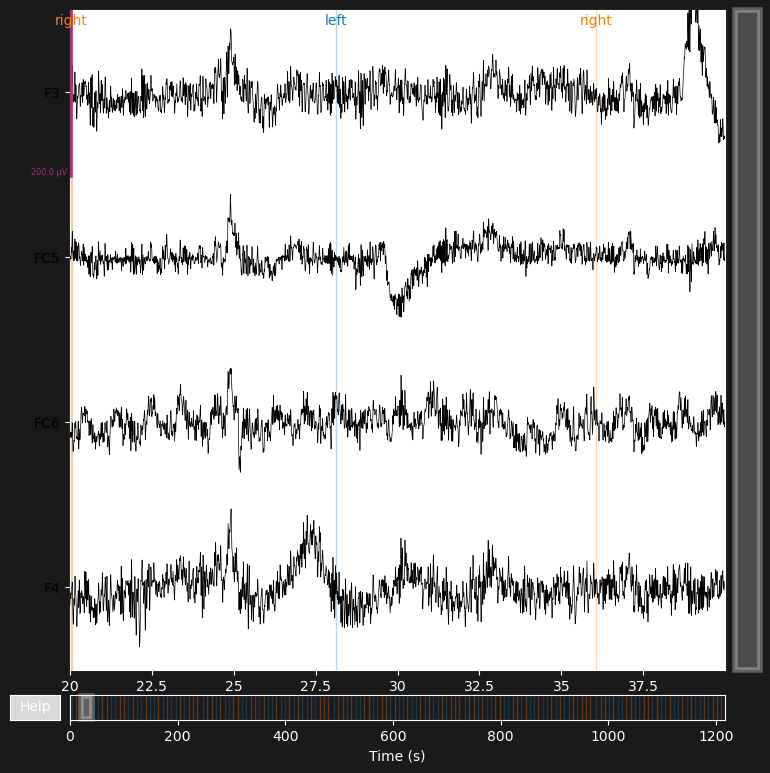

In [4]:
start_sec = 20
end_sec = 40

# Use a wider browser so the channel labels remain visible on the left.
mne.viz.set_browser_backend("matplotlib")
plot_channels = [c for c in ["FC5", "FC6", "F3", "F4"] if c in ch_names_raw]

# Keep every trial in the same class the same color.
annotation_colors = {
    description: (
        "tab:blue" if description == "left"
        else "tab:orange" if description == "right"
        else "tab:gray"
    )
    for description in raw.annotations.description
    if description in {"left", "right"}
}

fig = raw.plot(
    start=start_sec,
    duration=end_sec - start_sec,
    picks=plot_channels,
    n_channels=len(plot_channels),
    scalings=dict(eeg=100e-6),
    annotation_colors=annotation_colors,
)
plt.show()

### Channel Locations (Montage)

So far MNE only knows channel *names*, not where they sit on the scalp. A **montage**
attaches 3-D sensor coordinates to each name, which unlocks topographic (scalp-map)
plotting. All 14 EPOC X channel names are standard 10-20 labels, so MNE's built-in
`standard_1020` montage covers them directly — no manual coordinates needed.

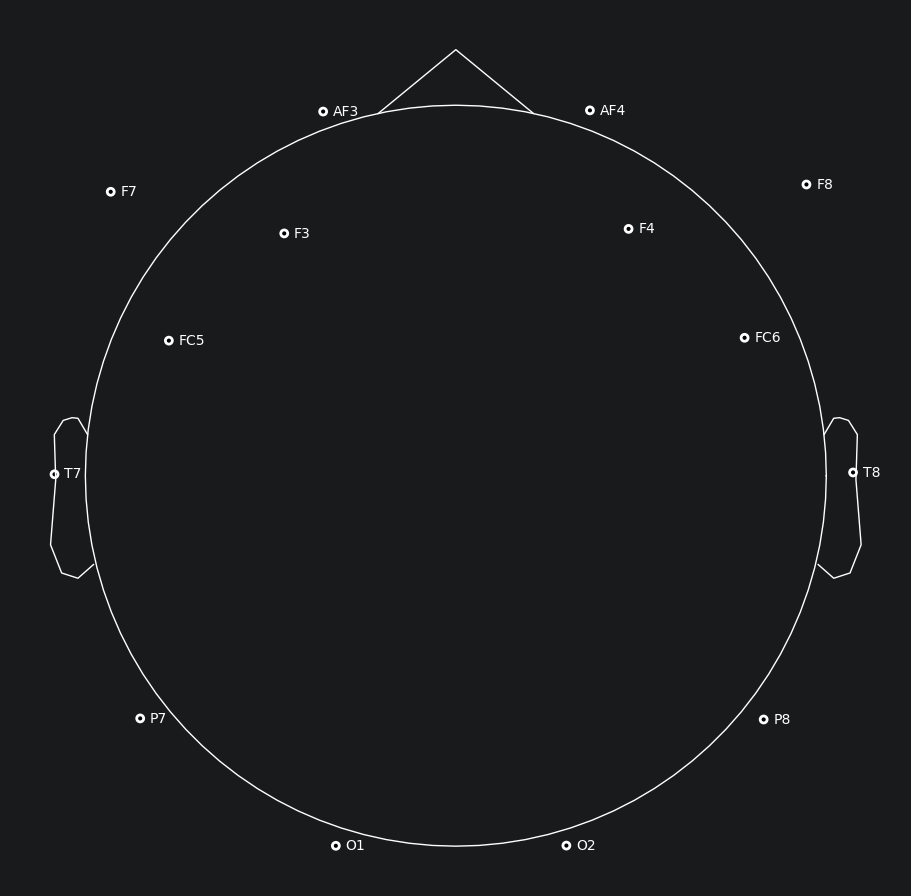

In [5]:
raw.set_montage("standard_1020")
raw.plot_sensors(show_names=True, sphere="auto")
plt.show()

### Power Spectral Density (PSD)

The time-domain plot tells us little about *which* frequencies dominate. `compute_psd()`
runs Welch's method per channel and `.plot()` overlays them. Expect a strong low-frequency
slope (1/f-like) and — since we haven't notch-filtered yet — a spike at **50 Hz** (Tokyo mains
frequency) and its harmonic near 100 Hz. (Here we cannot see a spike at 50 Hz since Emotive automatically applies notch filter before saving EEG data)

/opt/anaconda3/envs/MotorImageryDemo/lib/python3.10/site-packages/mne/viz/utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


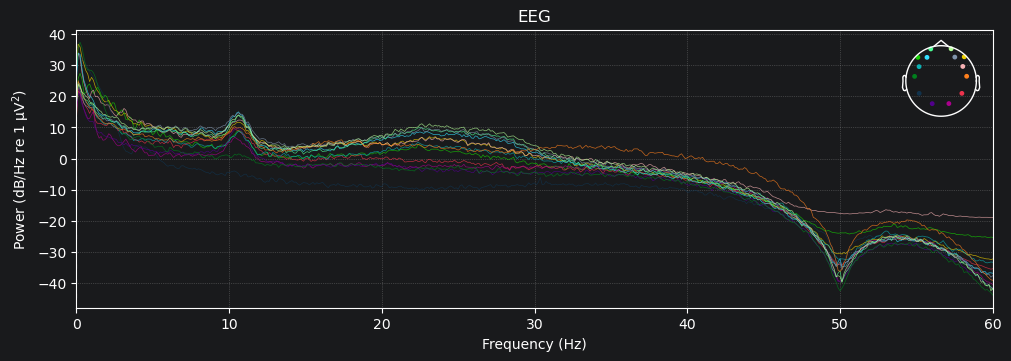

In [6]:
spectrum = raw.compute_psd(fmax=60)
spectrum.plot(average=False, amplitude=False)
plt.show()

## 2. Preprocess with MNE (Notch → Bandpass → CAR) and Epoch

Section 1 concatenated all sessions into one continuous `raw`. We preprocess that
concatenated Raw directly. MNE inserts `BAD boundary` annotations between sessions, and
`reject_by_annotation=True` excludes any epoch that would cross a session boundary.

We apply, in order:
1. **`raw.notch_filter()`** — remove the 50 Hz mains-power noise
2. **`raw.filter()`** — retain the 1–40 Hz EEG frequency range
3. **`raw.set_eeg_reference("average")`** — Common Average Reference (CAR)
4. **`mne.events_from_annotations()` + `mne.Epochs`** — cut out each 4-second MI trial

### 2-1. Remove Noise

In [7]:
# === Preprocessing controls ===
# NOTCH_HZ: remove electrical mains noise at this frequency.
# Use 50.0 in Japan/Europe, 60.0 in North America, or None to disable it.
NOTCH_HZ = 50.0

# BANDPASS_HZ = (low, high): retain EEG frequencies between low and high Hz.
# The default 1–40 Hz range removes slow drifts and attenuates high-frequency noise.
# Examples: (8.0, 30.0) for mu + beta, or (8.0, 13.0) for mu only.
BANDPASS_HZ = (1.0, 40.0)

# APPLY_CAR: True applies Common Average Reference across all EEG channels.
# Set it to False to keep the original channel references.
APPLY_CAR = True

In [8]:
eeg = raw.copy()
# remove line noise
if NOTCH_HZ is not None:
    eeg.notch_filter(freqs=NOTCH_HZ, picks="eeg")
# bandpass filter EEG
eeg.filter(l_freq=BANDPASS_HZ[0], h_freq=BANDPASS_HZ[1], picks="eeg")
# apply common average reference
if APPLY_CAR:
    eeg.set_eeg_reference("average")

Let's check the effect of filtering and CAR on the raw signal with PSD.

/opt/anaconda3/envs/MotorImageryDemo/lib/python3.10/site-packages/mne/viz/utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


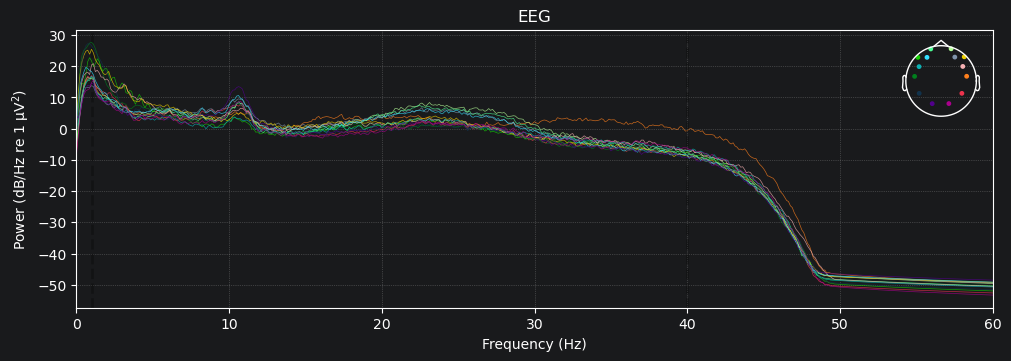

In [9]:
# Power Spectral Density (PSD)
spectrum = eeg.compute_psd(fmax=60)
spectrum.plot(average=False, amplitude=False)
plt.show()

### 2-2. Epoch (cut out trials)

#### Extract and inspect events

- Convert the trial annotations into Left and Right event IDs, then plot their timing across the recording.

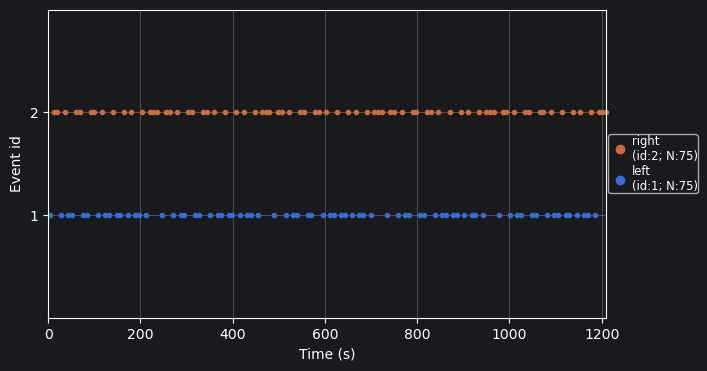

In [10]:
event_dict = {"left": 1, "right": 2}
events, _ = mne.events_from_annotations(eeg, event_id=event_dict)

# Plot the timing and class of all detected trials.
mne.viz.plot_events(
    events,
    sfreq=eeg.info["sfreq"],
    first_samp=eeg.first_samp,
    event_id=event_dict,
)
plt.show()

#### Create epochs

- Extract each trial from **−4 to +4 seconds** relative to MI onset: rest from −4 to −1 s,
  cue from −1 to 0 s, and MI from 0 to +4 s.

In [11]:
epochs = mne.Epochs(
    eeg,
    events,
    event_id=event_dict,
    tmin=-4.0,
    tmax=4.0,
    baseline=None,
    picks="eeg",
    preload=True,
    reject_by_annotation=True,
)

# Epochs crossing session boundaries are rejected automatically.
epochs

<Epochs | 150 events (all good), -4 – 4 s (baseline off), ~32.9 MiB, data loaded,
 'left': 75
 'right': 75>

## 3. Inspect Preprocessed Signals and Reject Bad Trials

The recording has 14 EPOC X channels. The figure below maps the headset channel names to
the brain regions underneath.

| EPOC X channel locations | Motor cortex location |
|---|---|
| ![EPOC X channel placement](assets/epoc_channel_locations.png) | ![Motor cortex region](assets/motor_cortex_regions.png) |

_Source: [channel locations](https://www.researchgate.net/figure/Emotiv-EPOC-headset-14-channel-placement-with-two-reference-channels_fig2_309427804) · [motor cortex](https://www.researchgate.net/figure/Primary-brain-regions-Motor-cortex-is-the-region-in-charge-of-planning-control-and_fig2_331905251)._

Inspect every channel in each trial and record trials containing large artifacts or unstable signals.

### Inspect one trial

Set `trial` to an epoch index (starting from 0). Set `channels` to a list of channel names to limit the display, or `None` to display all EEG channels. The red vertical line marks the motor-imagery onset at 0 s.

Trial index: 6


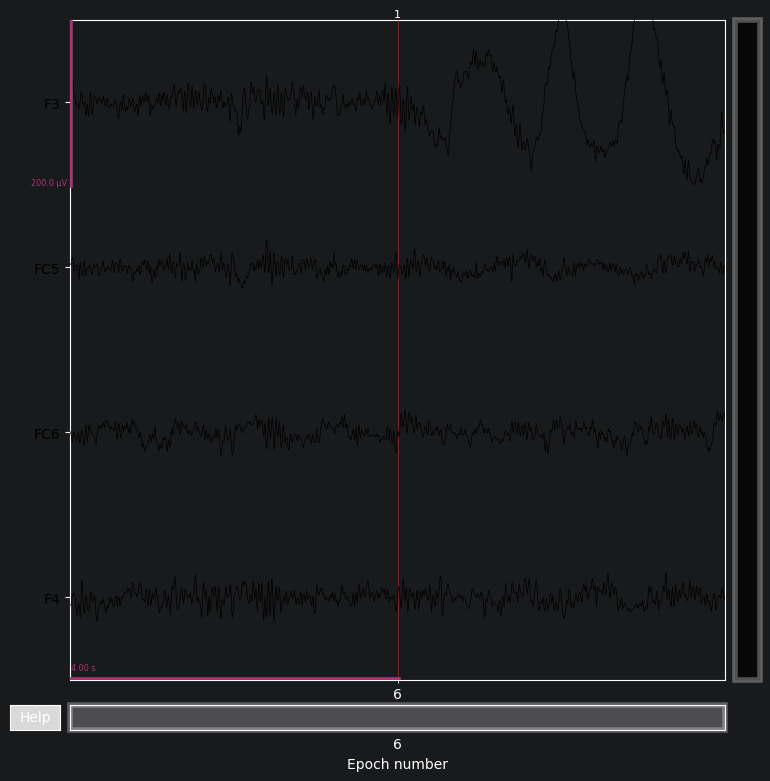

In [12]:
trial = 6
# channels = None  # e.g. ["FC5", "FC6", "F3", "F4"]
channels = ["FC5", "FC6", "F3", "F4"]

selected_channels = epochs.ch_names if channels is None else channels
print(f"Trial index: {trial}")
epochs[trial].plot(
    n_epochs=1,
    picks=selected_channels,
    n_channels=len(selected_channels),
    scalings={"eeg": 100e-6},
    events=True,
    event_color="red",
)
plt.show()

### Mark bad trials

A few high-amplitude trials (movement / blink artifacts) carry so much power that they
dominate the trial-averaged power in Section 4 and bury the ERD/ERS. We flag them
**automatically**: any trial whose overall variance exceeds `THRESHOLD_K` times the median
trial is marked bad. Add any extra indices you spot by eye to `bad_trial_list`.

In [16]:
# Auto-detect artifact trials: those whose variance is far above the typical trial.
THRESHOLD_K = 1  # lower = stricter (rejects more trials)

trial_power = epochs.get_data().var(axis=(1, 2))  # one power value per trial
auto_bad = np.where(trial_power > np.median(trial_power) * THRESHOLD_K)[0]

# Add any extra trials you flagged by eye, e.g. extra_bad = [3, 18]
extra_bad = [6]
bad_trial_list = sorted(set(auto_bad.tolist()) | set(extra_bad))
print(f"Bad trials: {bad_trial_list}")

Bad trials: [5, 6, 8, 9, 10, 11, 12, 17, 18, 20, 21, 24, 25, 27, 28, 29, 31, 32, 37, 38, 41, 44, 47, 48, 52, 53, 54, 58, 59, 63, 65, 67, 68, 69, 72, 73, 75, 76, 77, 81, 82, 83, 84, 85, 86, 88, 92, 93, 94, 95, 96, 97, 99, 100, 101, 103, 108, 117, 120, 122, 124, 125, 126, 128, 129, 131, 133, 134, 138, 139, 140, 141, 145, 147, 149]


### Remove bad trials

Create a cleaned copy after removing the selected trials.

In [17]:
epochs_clean = epochs.copy()
epochs_clean.drop(bad_trial_list, reason="USER")

print(f"Before: {len(epochs)} trials")
print(f"After : {len(epochs_clean)} trials")

Before: 150 trials
After : 75 trials


## 4. Visualize ERD/ERS

In [18]:
bands = {"Mu (8-12Hz)": (8, 12), "Beta (13-30Hz)": (13, 30)}

epochs_band = {}

for name, (lo, hi) in bands.items():
    raw_band = raw.copy()
    # Band-pass on continuous data
    raw_band.filter(l_freq=lo, h_freq=hi, picks="eeg", method="iir", verbose=False)
    # Common Average Reference
    raw_band.set_eeg_reference(ref_channels="average", projection=False, verbose=False)
    # Epoch after filtering and CAR
    epochs_band[name] = mne.Epochs(
        raw_band, events, event_id=event_dict,
        tmin=-4, tmax=4,
        baseline=None, picks="eeg", preload=True,
        reject_by_annotation=True, verbose=False
    )
    # Remove bad trials
    epochs_band[name].drop(bad_trial_list, reason="USER")

print({name: len(ep) for name, ep in epochs_band.items()})

{'Mu (8-12Hz)': 75, 'Beta (13-30Hz)': 75}


In [19]:
def power_squared(x):
    return x ** 2

# Smoothing window for the averaged power (in seconds). The instantaneous power is
# very jittery, so we smooth it with a moving average before computing % change.
SMOOTH_SEC = 0.5

def smooth(x, win):
    if win <= 1:
        return x
    # mode="nearest" extends the edge values instead of zero-padding, avoiding an
    # artificial power dip at the start/end of each epoch.
    return uniform_filter1d(x, size=win, axis=-1, mode="nearest")

def compute_erd_ers(power, times, baseline_start, baseline_end):
    fs = 1.0 / (times[1] - times[0])
    power_avg = smooth(power.mean(axis=0), int(SMOOTH_SEC * fs))  # smoothed trial-averaged power (ch, times)
    baseline_mask = (times >= baseline_start) & (times <= baseline_end)
    R = power_avg[:, baseline_mask].mean(axis=-1, keepdims=True)  # Mean power during baseline
    erd_ers = (power_avg - R) / R * 100
    return erd_ers

def compute_erd_ers_by_condition(epochs_obj, power_fn, times, baseline_start, baseline_end, condition):
    data = epochs_obj[condition].get_data()  # Restrict to one condition first, shape (n_trials, ch, times)
    power = power_fn(data)
    return compute_erd_ers(power, times, baseline_start, baseline_end)

times = epochs_band['Mu (8-12Hz)'].times
BASELINE_START = -3.0
BASELINE_END = -1.0

LEFT_COND = "left"
RIGHT_COND = "right"

# --- Mu Band ---
erd_mu_left  = compute_erd_ers_by_condition(epochs_band['Mu (8-12Hz)'], power_squared, times, BASELINE_START, BASELINE_END, LEFT_COND)
erd_mu_right = compute_erd_ers_by_condition(epochs_band['Mu (8-12Hz)'], power_squared, times, BASELINE_START, BASELINE_END, RIGHT_COND)

# --- Beta Band ---
erd_beta_left  = compute_erd_ers_by_condition(epochs_band['Beta (13-30Hz)'], power_squared, times, BASELINE_START, BASELINE_END, LEFT_COND)
erd_beta_right = compute_erd_ers_by_condition(epochs_band['Beta (13-30Hz)'], power_squared, times, BASELINE_START, BASELINE_END, RIGHT_COND)

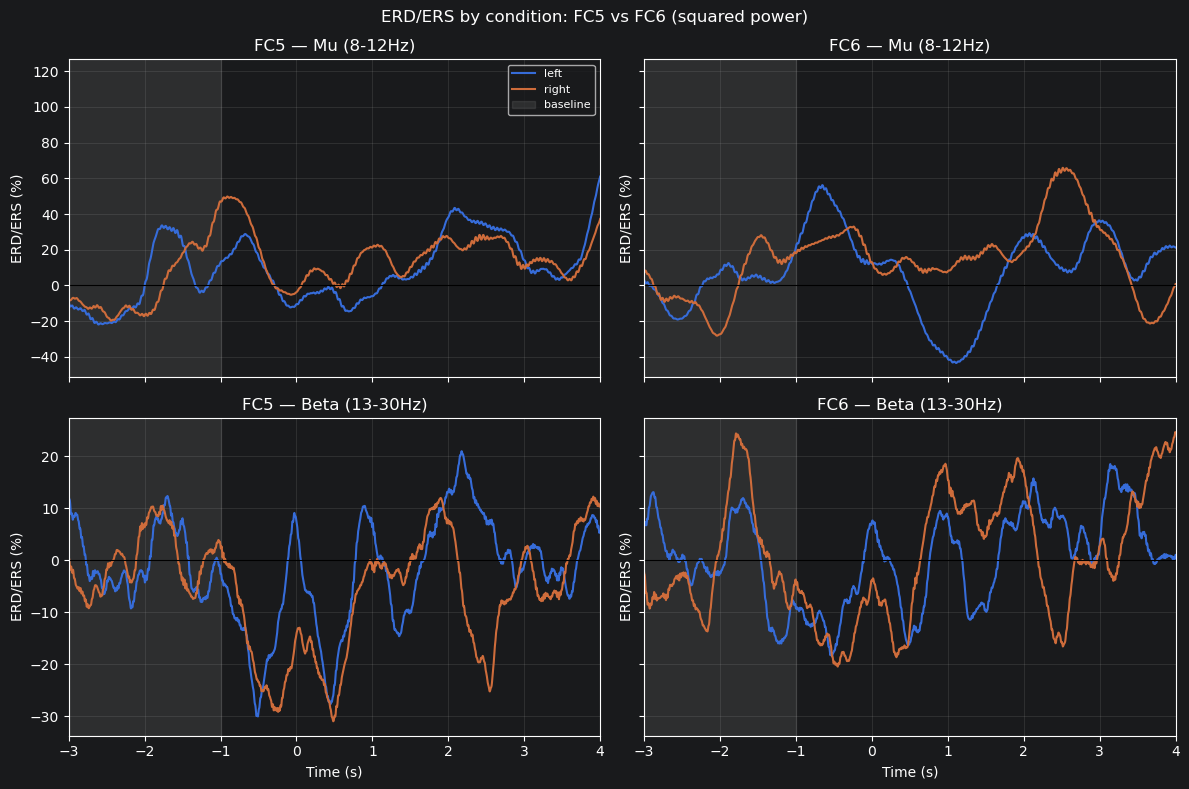

In [20]:
ch_left = "FC5"
ch_right = "FC6"

ch_idx_left = epochs_band['Mu (8-12Hz)'].ch_names.index(ch_left)
ch_idx_right = epochs_band['Mu (8-12Hz)'].ch_names.index(ch_right)

plot_data = [
    ("FC5 — Mu (8-12Hz)",    erd_mu_left[ch_idx_left],    erd_mu_right[ch_idx_left]),
    ("FC6 — Mu (8-12Hz)",    erd_mu_left[ch_idx_right],   erd_mu_right[ch_idx_right]),
    ("FC5 — Beta (13-30Hz)", erd_beta_left[ch_idx_left],  erd_beta_right[ch_idx_left]),
    ("FC6 — Beta (13-30Hz)", erd_beta_left[ch_idx_right], erd_beta_right[ch_idx_right]),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey='row')

for ax, (title, y_left_cond, y_right_cond) in zip(axes.flat, plot_data):
    ax.plot(times, y_left_cond, label=LEFT_COND, linewidth=1.5)
    ax.plot(times, y_right_cond, label=RIGHT_COND, linewidth=1.5)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvspan(BASELINE_START, BASELINE_END, color="gray", alpha=0.2, label="baseline")
    ax.set_title(title)
    ax.set_ylabel("ERD/ERS (%)")
    ax.set_xlim(BASELINE_START, times[-1])  # Start the view from the baseline onward
    ax.grid(alpha=0.2)

for ax in axes[-1]:
    ax.set_xlabel("Time (s)")

axes[0, 0].legend(fontsize=8)
fig.suptitle("ERD/ERS by condition: FC5 vs FC6 (squared power)")
fig.tight_layout()
plt.show()